# Remote Sensing Workflow

## Imports

In [125]:
# GIS and spatial data libraries
import rasterio
from rasterio.crs import CRS
from rasterio.plot import show
from rasterio.transform import xy
from rasterio.warp import reproject, Resampling, transform_bounds
import pyproj
from pyproj import Transformer
from affine import Affine
from osgeo import gdal
gdal.UseExceptions()
from shapely.geometry import box

# Data analysis and machine learning libraries
from itertools import combinations
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import skew
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Data access libraries
import json
import sys
from pathlib import Path
import pip
import platform

# Check for load errors
print(
    "All libraries imported successfully\n" 
    f"gdal v.{gdal.__version__}\n"
    f"pip v.{pip.__version__}\n"
    f"Python v{platform.python_version()}"
)

All libraries imported successfully
gdal v.3.13.3
pip v.25.2
Python v3.13.7


In [37]:
# Verify paths
print(
    f"Working directory: {Path.cwd()}\n" 
    f"Python executable: {sys.executable}\n"
    f"Datasets folder exists: {Path("Datasets").exists()}\n"
    f"Assets folder exists: {Path("Assets").exists()}\n"
    f"Data Export folder exists: {Path("Data Export").exists()}\n"
)

Working directory: c:\Users\matil\Documents\GitHub\GIS-Project
Python executable: c:\Users\matil\AppData\Local\Programs\Python\Python313\python.exe
Datasets folder exists: True
Assets folder exists: True
Data Export folder exists: True



## Data Cleaning

### OpenTopography DEM

In [14]:
# Load DEM raster and metadata
DEM_path = r"Datasets\opentopography\DEM.tif"

with rasterio.open(DEM_path) as DEM_src:

    elevation = DEM_src.read(1)
    elevation_transform = DEM_src.transform
    elevation_crs = DEM_src.crs
    elevation_nodata = DEM_src.nodata

    DEM_metadata = {
        "File Name": os.path.basename(DEM_path),
        "Type": type(elevation).__name__,
        "Size": elevation.size,
        "Shape": elevation.shape,
        "Max": elevation.max(),
        "Min": elevation.min(),
        "NoData": DEM_src.nodata,
        "CRS": DEM_src.crs, 
        "Resolution": DEM_src.res,
        "Bounds": DEM_src.bounds
    }

DEM_metadata

{'File Name': 'DEM.tif',
 'Type': 'ndarray',
 'Size': 596070,
 'Shape': (895, 666),
 'Max': np.float32(1503.917),
 'Min': np.float32(-32767.0),
 'NoData': -32767.0,
 'CRS': CRS.from_wkt('PROJCS["NAD83(CSRS) / Canada Atlas Lambert",GEOGCS["NAD83(CSRS)",DATUM["NAD83_Canadian_Spatial_Reference_System",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6140"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4617"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",49],PARAMETER["central_meridian",-95],PARAMETER["standard_parallel_1",49],PARAMETER["standard_parallel_2",77],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3979"]]'),
 'Resolution': (30.0, 30.0),
 'Bounds': BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)}

In [40]:
# Transform DEM bounds
bounds_EPSG_4326 = transform_bounds(
    elevation_crs,
    "EPSG:4326",
    *DEM_metadata["Bounds"]
)

bounds_EPSG_32610 = transform_bounds(
    elevation_crs,
    "EPSG:32610",
    *DEM_metadata["Bounds"]
)

print(
    f"DEM export EPSG:3979: {tuple(DEM_metadata["Bounds"])}\n"
    f"EPSG:4326: {bounds_EPSG_4326 }\n"
    f"EPSG:32610: {bounds_EPSG_32610}" 
)

DEM export EPSG:3979: (-1980000.0, 473550.0, -1960020.0, 500400.0)
EPSG:4326: (-123.29291260026993, 49.25527457420543, -122.8853009908351, 49.55076853448343)
EPSG:32610: (478779.52998752374, 5455842.720256816, 508333.4824226063, 5488685.934225603)


In [41]:
# Bound Selection for AOI
transformer = pyproj.Transformer.from_crs("EPSG:32610", "EPSG:4326", always_xy=True)

xmin_geo, ymin_geo = transformer.transform(bounds_EPSG_32610[0], bounds_EPSG_32610[1])
xmax_geo, ymax_geo = transformer.transform(bounds_EPSG_32610[2], bounds_EPSG_32610[3])

print(
    f"xmin/W:: {xmin_geo}", 
    f"ymin/S: {ymin_geo}", 
    f"xmax/E: {xmax_geo}", 
    f"ymax/N: {ymax_geo}"
)

geometry = box(xmin_geo, ymin_geo, xmax_geo, ymax_geo)

geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {},
        "geometry": geometry.__geo_interface__
    }]
}

output_geojson_path = Path("Assets") / "dem_AOI.geojson"
with output_geojson_path.open("w", encoding="utf-8") as f:
    json.dump(geojson, f, indent=2)

xmin/W:: -123.29161663788408 ymin/S: 49.25498431356825 xmax/E: -122.88478957342635 ymax/N: 49.55071922714218


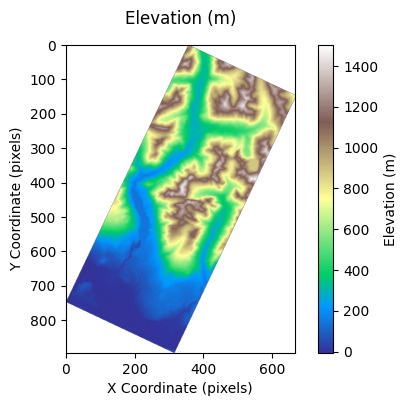

In [42]:
# NoData Mask
valid_mask = elevation != DEM_src.nodata

elevation_valid = np.where(
    valid_mask,
    elevation,
    np.nan
)

# Data visualization
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
image = ax.imshow(elevation_valid, cmap="terrain")
fig.colorbar(image, ax=ax, label="Elevation (m)")
ax.set_title("Elevation (m)", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### DEM, Sentinel, and Dynamic World V1 Data Load

#### Load Sentinel Data

In [48]:
# Load sentinel bands and metadata 
def get_composite_data(ndvi_data_path):

    with rasterio.open(ndvi_data_path) as sentinel_src:

        bands = {
            "B4": sentinel_src.read(1),
            "B3": sentinel_src.read(2),
            "B2": sentinel_src.read(3),
            "B8_NIR": sentinel_src.read(4),
            "nd": sentinel_src.read(5),
        }

        raster_info = {
            "crs": sentinel_src.crs,
            "transform": sentinel_src.transform,
            "nodata": sentinel_src.nodatavals[0],
            "shape": sentinel_src.shape,
        }

        composite_metadata = {
            "File Name": os.path.basename(sentinel_src.name),
            "CRS": sentinel_src.crs,
            "Bounds": sentinel_src.bounds,
            "Width": sentinel_src.width,
            "Height": sentinel_src.height,
            "Tags": sentinel_src.tags(),
            "Resolution": sentinel_src.res,
            "NoData values": sentinel_src.nodatavals,
            "Transform": sentinel_src.transform,
            "Descriptions": sentinel_src.descriptions,
            "B4 Min/Max": (np.nanmin(bands["B4"]), np.nanmax(bands["B4"])),
            "B8 Min/Max": (np.nanmin(bands["B8_NIR"]), np.nanmax(bands["B8_NIR"])),
            "B2 Min/Max": (np.nanmin(bands["B2"]), np.nanmax(bands["B2"])),
            "B3 Min/Max": (np.nanmin(bands["B3"]), np.nanmax(bands["B3"])),
            "NDVI Min/Max": (np.nanmin(bands["nd"]), np.nanmax(bands["nd"])),      
        }

    return {
        "bands": bands,
        "raster_info": raster_info, 
        "metadata": composite_metadata,
    }

In [49]:
# Load clean sentinel NDVI
def get_ndvi(ndvi_data_path):
    dataset = get_composite_data(ndvi_data_path)
    nd_band = dataset["bands"]["nd"]
    no_data_value = dataset["raster_info"]["nodata"]

    if no_data_value is None or np.isnan(no_data_value):
        no_data_mask = np.isfinite(nd_band)
    else:
        no_data_mask = ((nd_band != no_data_value) & np.isfinite(nd_band))

    dataset_clean = np.where(no_data_mask, nd_band, np.nan)
    
    return dataset_clean

#### DEM Reproject

In [ ]:
# Sample sentinel metadata for reproject parameters
reproject_sample_path = r"Datasets\sentinel_2_l2a\sentinel_l2a_202608_10UDV_composite.tif"
sentinel_shape = (get_composite_data(reproject_sample_path))["raster_info"]["shape"]
sentinel_transform = (get_composite_data(reproject_sample_path))["raster_info"]["transform"]
sentinel_crs = (get_composite_data(reproject_sample_path))["raster_info"]["crs"]

In [18]:
# Reproject DEM onto sentinel grid
elevation_reproject = np.empty(sentinel_shape, dtype=np.float32)

reproject(
    source=elevation_valid,
    destination=elevation_reproject,
    src_transform=elevation_transform,
    src_crs=elevation_crs,
    dst_transform=sentinel_transform,
    dst_crs=sentinel_crs,
    dst_nodata=np.nan,
    shape=sentinel_shape,
    resampling=Resampling.bilinear
)

print(f"DEM Reproject shape: {elevation_reproject.shape}")

DEM Reproject shape: (3293, 2962)


In [52]:
# Crop DEM reproject 
valid_DEM = np.isfinite(elevation_reproject)
rows, cols = np.where(valid_DEM)

if rows.size == 0:
    raise ValueError("elevation_reproject contains no finite data")

row0, row1 = rows.min(), rows.max() + 1  
col0, col1 = cols.min(), cols.max() + 1
elevation_crop = elevation_reproject[row0:row1, col0:col1]

print(f"DEM crop shape: {elevation_crop.shape}")

DEM crop shape: (2486, 1043)


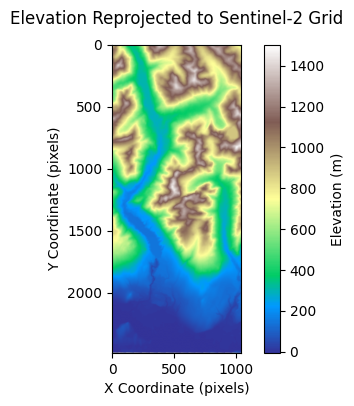

In [53]:
# Data visualization
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(elevation_crop, cmap="terrain")
cbar = fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set_title("Elevation Reprojected to Sentinel-2 Grid", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

#### GDAL Slope

In [21]:
# Create a GDAL in-memory dataset for the cropped DEM
dem_array = elevation_crop.astype(np.float32)
rows, cols = dem_array.shape

print("Rows:", rows)
print("Columns:", cols)

driver = gdal.GetDriverByName("MEM")
ds = driver.Create(
    "",
    cols,
    rows,
    1,
    gdal.GDT_Float32
)

# Translate the GDAL geotransform to match the cropped DEM's in sentinel grid
crop_transform = sentinel_transform * Affine.translation(col0, row0)
ds.SetGeoTransform(crop_transform.to_gdal())
ds.SetProjection(sentinel_crs.to_wkt())

band = ds.GetRasterBand(1)
band.WriteArray(dem_array)
band.SetNoDataValue(np.nan)

slope_ds = gdal.DEMProcessing(
    "",
    ds,
    "slope",
    format="MEM",
    slopeFormat="degree",
    alg="Horn"
)

slope_band = slope_ds.GetRasterBand(1)
slope_gdal_array = slope_band.ReadAsArray()
slope_nodata = slope_band.GetNoDataValue()
slope_gdal_array = np.where(
    slope_gdal_array == slope_nodata,
    np.nan,
    slope_gdal_array
)

Rows: 2486
Columns: 1043


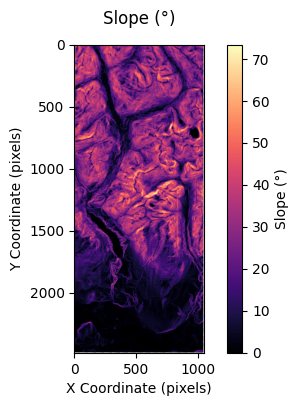

In [65]:
# Data visualization
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(slope_gdal_array, cmap="magma")
cbar = fig.colorbar(im, ax=ax, label="Slope (°)")
ax.set_title("Slope (°)", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

#### Sentinel Data Clean

In [ ]:
# Prepare clean sentinel datasets
sentinel_ndvi_datasets = []
years = range(2024, 2027)

for year in years:
    tif_path = rf"Datasets\sentinel_2_l2a\sentinel_l2a_{year}08_10UDV_composite.tif"
    sentinel_ndvi_datasets.append(get_ndvi(tif_path))

    metadata = get_composite_data(tif_path)
    print(metadata["metadata"])

{'File Name': 'sentinel_l2a_202408_10UDV_composite.tif', 'CRS': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 10N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32610"]]'), 'Bounds': BoundingBox(left=478770.0, bottom=5455800.0, right=508390.0, top=5488730.0), 'Width': 2962, 'Height': 3293, 'Tags': {'AREA_OR_POINT': 'Area'}, 'Resolution': (10.0, 10.0), 'NoData values': (-9999.0, -9999.0, -9999.0, -9999.0, -9999.0), 'Transform': Affine(10.0, 0.0, 478770.0,
       0.0, -10.0, 5488730.0), 'D

In [67]:
for year in years:
    path = rf"Datasets\sentinel_2_l2a\sentinel_l2a_{year}08_10UDV_composite.tif"
    info = get_composite_data(path)["raster_info"]
    assert info["shape"] == sentinel_shape, f"{year}: shape {info['shape']} != {sentinel_shape}"
    assert info["transform"] == sentinel_transform, f"{year}: transform differs from reference"
    assert info["crs"] == sentinel_crs, f"{year}: CRS differs"
print("All composites share the reference grid")

All composites share the reference grid


In [68]:
# Crop sentinel
crop = (slice(row0, row1), slice(col0, col1))
ndvi_crop = []

for sentinel_ndvi_dataset in sentinel_ndvi_datasets:
    dataset_crop = sentinel_ndvi_dataset[crop]
    ndvi_crop.append(dataset_crop)

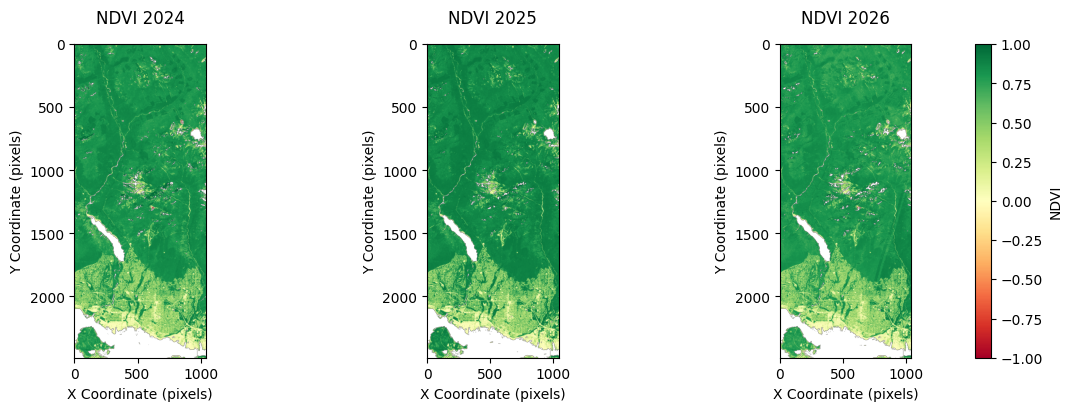

In [69]:
# Data visualization
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=100, layout="constrained")

for ax, year, ndvi_data in zip(axes, years, ndvi_crop):
    image = ax.imshow(ndvi_data, cmap="RdYlGn", vmin=-1, vmax=1) 
    ax.set_title(f"NDVI {year}", pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

fig.colorbar(image, ax=axes, label="NDVI")
plt.show()

#### Dynamic World V1 Data

In [70]:
# Load DWV1 bands and metadata 
dynamic_world_tif_path = r"Datasets\dynamic_world_V1\dynamic_world_20260807_T10UDV.tif"

with rasterio.open(dynamic_world_tif_path) as dw_src:
    dw_data = dw_src.read(1)
    dw_crs = dw_src.crs
    dw_transform = dw_src.transform
    dw_shape = dw_src.shape
    dw_nodata = dw_src.nodata

    dw_metadata = {
        "File Name": os.path.basename(dw_src.name),
        "CRS": dw_src.crs,
        "Bounds": dw_src.bounds,
        "Width": dw_src.width,
        "Height": dw_src.height,
        "Tags": dw_src.tags(),
        "Resolution": dw_src.res,
        "NoData values": dw_src.nodatavals,
        "Transform": dw_src.transform,
    }

dw_metadata

{'File Name': 'dynamic_world_20260807_T10UDV.tif',
 'CRS': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 10N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32610"]]'),
 'Bounds': BoundingBox(left=478770.0, bottom=5455800.0, right=508390.0, top=5488730.0),
 'Width': 2962,
 'Height': 3293,
 'Tags': {'AREA_OR_POINT': 'Area'},
 'Resolution': (10.0, 10.0),
 'NoData values': (255.0,),
 'Transform': Affine(10.0, 0.0, 478770.0,
        0.0, -10.0, 5488730.0)}

In [71]:
# Reproject DWV1 onto sentinel grid
dw_mask = dw_data != dw_nodata
dw_clean = np.where(dw_mask, dw_data, np.nan)
dw_reproject = np.empty(sentinel_shape, dtype=np.float32)

reproject(
    source=dw_clean,
    destination=dw_reproject,
    src_transform=dw_transform,
    src_crs=dw_crs,
    dst_transform=sentinel_transform,
    dst_crs=sentinel_crs,
    dst_nodata=np.nan,
    shape=sentinel_shape,
    resampling=Resampling.nearest
)

dw_crop = dw_reproject[crop]

print(f"DWV1 Reproject shape: {dw_reproject.shape}")

DWV1 Reproject shape: (3293, 2962)


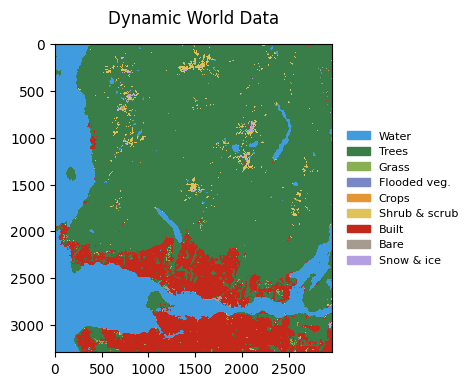

In [ ]:
# Data visualization
dw_names = ["Water", "Trees", "Grass", "Flooded veg.", "Crops", "Shrub & scrub", "Built", "Bare", "Snow & ice"]
dw_colors = ["#419BDF", "#397D49", "#88B053", "#7A87C6", "#E49635", "#DFC35A", "#C4281B", "#A59B8F", "#B39FE1"]
dw_cmap = ListedColormap(dw_colors)
dw_norm = BoundaryNorm(np.arange(-0.5, 9.5, 1), dw_cmap.N)

fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
ax.imshow(dw_reproject, cmap=dw_cmap, norm=dw_norm, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(dw_colors, dw_names)],
          loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8)
ax.set_title("Dynamic World Data", pad=15)
plt.show()

## Data Analysis

### Temporal NDVI Change Statistics

In [ ]:
# Ensure matching dataset shapes
shared_datasets = [
    *ndvi_crop,
    elevation_crop,
    slope_gdal_array,
]

shared_mask = np.logical_and.reduce(
    [np.isfinite(data) for data in shared_datasets]
)

datasets_masked = [
    np.where(shared_mask, data, np.nan)
    for data in shared_datasets
]

datasets_masked.append(dw_crop)

for name, data in datasets.items():
    datasets_masked.append(data[shared_mask])
    print(f"{name} valid pixels: {datasets_masked[-1].size}")


NDVI 2024 valid pixels: 2318682
NDVI 2025 valid pixels: 2318682
NDVI 2026 valid pixels: 2318682
DW V1 valid pixels: 2318682
DEM valid pixels: 2318682
Slope valid pixels: 2318682


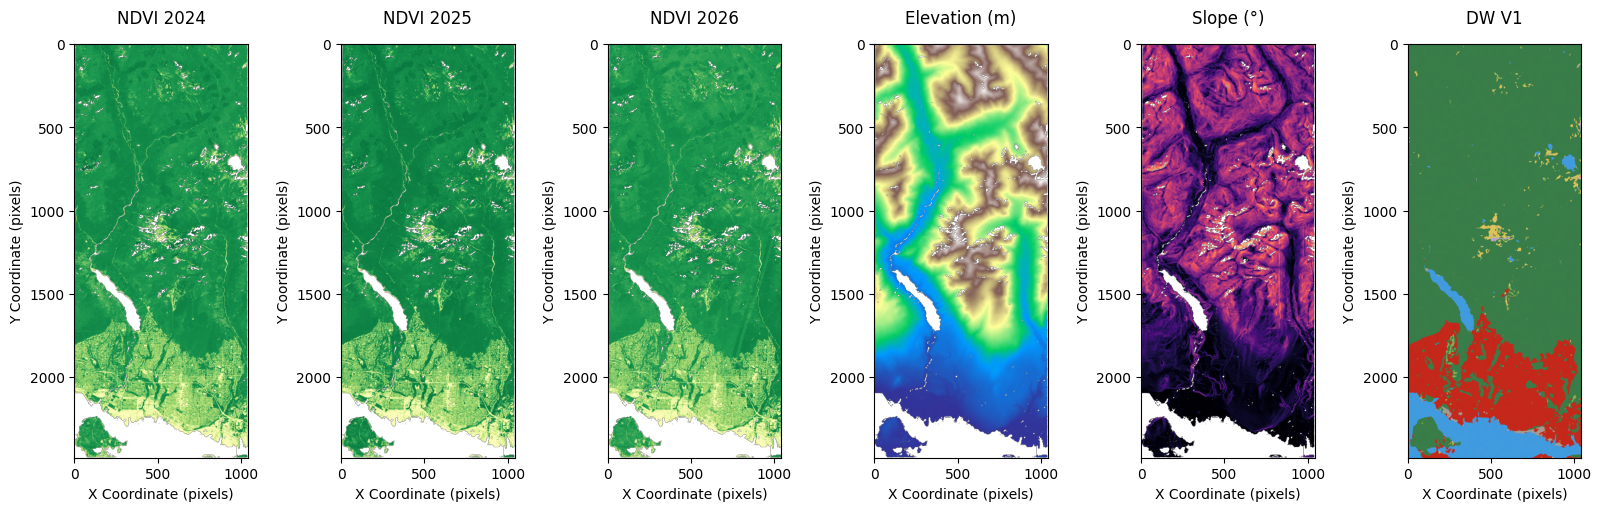

In [102]:
# Data visualization for NDVI, DEM, Slope, and DWV1
fig, axes = plt.subplots(1, 6, figsize=(16, 5), dpi=100, layout="constrained")
cmaps = ["RdYlGn", "RdYlGn", "RdYlGn", "terrain", "magma", dw_cmap]

labels_full = ["NDVI 2024","NDVI 2025","NDVI 2026", "Elevation (m)", "Slope (°)", "DW V1"]

for ax, label, data, cmap_name in zip(axes, labels_full, datasets_masked, cmaps):
    # Select dataset and specify axis labels
    im = ax.imshow(data, cmap=cmap_name)
    ax.set_title(label, pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

plt.show()

NDVI 2024 (Max, Min, Std, Mean, Med, Skew): [1.0, -1.0, 0.199, 0.733, 0.813, -2.028]
NDVI 2025 (Max, Min, Std, Mean, Med, Skew): [1.0, -1.0, 0.207, 0.771, 0.857, -2.068]
NDVI 2026 (Max, Min, Std, Mean, Med, Skew): [1.0, -1.0, 0.191, 0.72, 0.792, -2.035]
Elevation (m) (Max, Min, Std, Mean, Med, Skew): [1492.646, -0.038, 375.572, 556.099, 529.506, 0.22]
Slope (°) (Max, Min, Std, Mean, Med, Skew): [73.391, 0.0, 13.477, 20.672, 20.672, 0.19]
DW V1 (Max, Min, Std, Mean, Med, Skew): [8.0, 0.0, 1.966, 1.817, 1.0, 1.61]


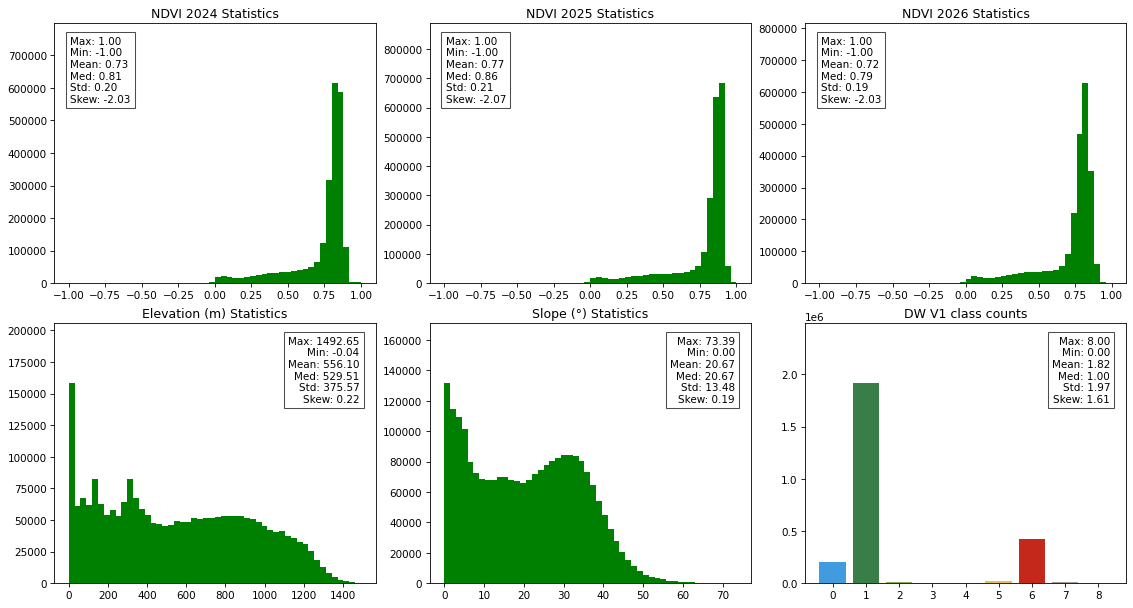

In [103]:
# Data statistics visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=75, layout="constrained")
axes_flat = axes.flatten()

labels_full = ["NDVI 2024","NDVI 2025","NDVI 2026", "Elevation (m)", "Slope (°)", "DW V1"]

for i, (label, data_matrix) in enumerate(zip(labels_full, datasets_masked)):
    # Compute statistics for the dataset
    v = data_matrix.ravel()[np.isfinite(data_matrix.ravel())]
    stats = [v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v)]
    print(f"{label} (Max, Min, Std, Mean, Med, Skew):", [round(float(x), 3) for x in stats])

    # Create histogram and set axis labels
    counts, bins, patches = axes_flat[i].hist(v, bins=50, color="green")
    axes_flat[i].set_title(f"{label} Statistics")
    max_bar_height = counts.max()
    axes_flat[i].set_ylim(0, max_bar_height * 1.3)

    # Specify text position and alignment 
    x_pos = 0.05 if i < 3 else 0.95
    h_align = 'left' if i < 3 else 'right'
    
    text = f"Max: {stats[0]:.2f}\nMin: {stats[1]:.2f}\nMean: {stats[3]:.2f}\nMed: {stats[4]:.2f}\nStd: {stats[2]:.2f}\nSkew: {stats[5]:.2f}"
    axes_flat[i].text(
        x_pos, 0.95, text, 
        transform=axes_flat[i].transAxes, 
        va='top', 
        ha=h_align, 
        bbox=dict(facecolor='white', alpha=0.7)
    )

    if label == "DW V1":
        vals, cnt = np.unique(v.astype(int), return_counts=True)
        axes_flat[i].bar(vals, cnt, color=[dw_colors[k] for k in vals])
        axes_flat[i].set_xticks(range(9))
        axes_flat[i].set_title("DW V1 class counts")
        continue

plt.show()

In [104]:
# Valid mask for NDVI temporal difference calculations
valid_ndvi_temporal = np.logical_and.reduce(
    [np.isfinite(ndvi) for ndvi in ndvi_crop]
)

# Function fro NDVI difference for date pairs
def diff_ndvi(start_date, end_date):
    difference = np.full(start_date.shape, np.nan, dtype=np.float32)
    np.subtract(end_date, start_date, out=difference, where=valid_ndvi_temporal)

    return difference

# Sorted date pairs by numerical index
date_pairs = sorted(
    combinations(range(len(ndvi_crop)), 2),
    key=lambda pair: pair[1] - pair[0],
)

# Compute NDVI differences for all date pairs
diff_ndvi_datasets = [
    diff_ndvi(ndvi_crop[start_date], ndvi_crop[end_date])
    for start_date, end_date in date_pairs
]

# Verify that the computed NDVI difference for 2024-2025 matches the expected result
diff_ndvi_2024_2025 = diff_ndvi(ndvi_crop[0], ndvi_crop[1])
np.array_equal(diff_ndvi_datasets[0], diff_ndvi_2024_2025, equal_nan=True)

True

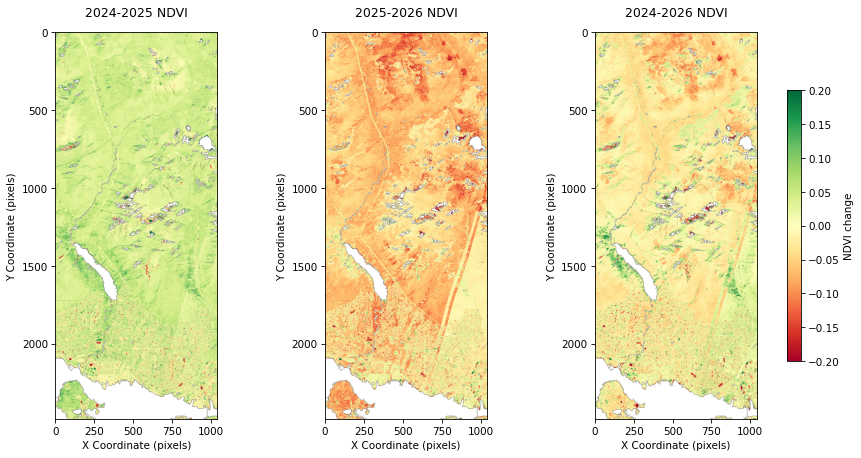

In [107]:
# NDVI difference visualization
fig, axes = plt.subplots(1, 3, figsize=(12, 6), dpi=75, layout="constrained")

temporal_labels = ["2024-2025 NDVI", "2025-2026 NDVI", "2024-2026 NDVI"]

for ax, label, data in zip(axes, temporal_labels, diff_ndvi_datasets):    # Select dataset and specify axis labels
    im = ax.imshow(data, cmap="RdYlGn", vmin=-0.2, vmax=0.2) 
    ax.set_title(label, pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

# Create overall colourbar for NDVI changes
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI change")

plt.show()

In [ ]:
# Display limits from the data for clipping
for (s, e), d in zip(date_pairs, diff_ndvi_datasets):
    v = np.abs(d[np.isfinite(d)])
    print(f"{years[s]}-{years[e]} |diff| p50/p90/p98/p99.9:",
          np.round(np.percentile(v, [50, 90, 98, 99.9]), 3),
          "| share beyond 0.2:", round(float((v > 0.2).mean()), 4))

2024-2025 |diff| p50/p90/p98/p99.9: [0.039 0.079 0.133 0.37 ] | share beyond 0.2: 0.0054
2025-2026 |diff| p50/p90/p98/p99.9: [0.055 0.1   0.148 0.354] | share beyond 0.2: 0.0057
2024-2026 |diff| p50/p90/p98/p99.9: [0.029 0.074 0.135 0.386] | share beyond 0.2: 0.0066


2024–2025 NDVI (Max, Min, Std, Mean, Med, Skew, P05, P95): [2.0, -1.523, 0.044, 0.038, 0.037, 1.193, -0.02, 0.095]
2025–2026 NDVI (Max, Min, Std, Mean, Med, Skew, P05, P95): [1.296, -2.0, 0.049, -0.051, -0.054, -2.03, -0.118, 0.024]
2024–2026 NDVI (Max, Min, Std, Mean, Med, Skew, P05, P95): [1.569, -1.872, 0.052, -0.013, -0.018, -0.423, -0.079, 0.067]


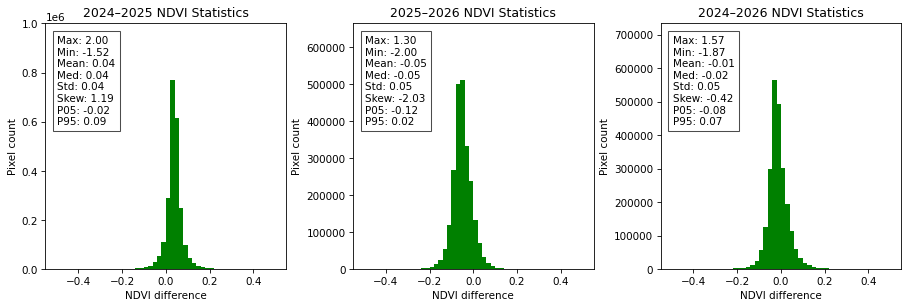

In [115]:
# NDVI difference statistics visualization
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=75, layout="constrained")
axes_flat = axes.flatten()

temporal_labels = ["2024–2025 NDVI", "2025–2026 NDVI", "2024–2026 NDVI"]

for i, (label, dataset) in enumerate(zip(temporal_labels, diff_ndvi_datasets)):
    # Compute statistics for the dataset
    v = dataset.ravel()[np.isfinite(dataset.ravel())]
    stats = [
        v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v),
        np.percentile(v, 5), np.percentile(v, 95)
    ]

    # Create histogram and set axis labels
    counts, bins, patches = axes_flat[i].hist(v, bins=50, range=(-0.5, 0.5), color="green")
    axes_flat[i].set_title(f"{label} Statistics")
    axes_flat[i].set_xlabel("NDVI difference")
    axes_flat[i].set_ylabel("Pixel count")
    axes_flat[i].set_ylim(0, counts.max() * 1.3)

    # Store metadata for display onto the histogram
    text = (
        f"Max: {stats[0]:.2f}\n"
        f"Min: {stats[1]:.2f}\n"
        f"Mean: {stats[3]:.2f}\n"
        f"Med: {stats[4]:.2f}\n"
        f"Std: {stats[2]:.2f}\n"
        f"Skew: {stats[5]:.2f}\n"
        f"P05: {stats[6]:.2f}\n"
        f"P95: {stats[7]:.2f}"
    )

    axes_flat[i].text(
        0.05, 0.95, text,
        transform=axes_flat[i].transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", alpha=0.7)
    )

    # Print statistics
    print(
            f"{label} (Max, Min, Std, Mean, Med, Skew, P05, P95):",
            [round(float(x), 3) for x in stats]
    )

plt.show()

In [119]:
# NDVI change statistics for all date pairs
t = 0.05  # NDVI change threshold

# Create empty dictionary to store statistics for each date pair
stats_by_pair = {}

# Loop through date pairs to calculate statistics
for (start, end), diff in zip(date_pairs, diff_ndvi_datasets):
    diff_values = diff[valid_ndvi_temporal]
    start_mean = np.mean((ndvi_crop[start][valid_ndvi_temporal])[start])
    end_mean = np.mean((ndvi_crop[start][valid_ndvi_temporal])[end])
    mean_change = np.mean(diff_values)
    valid_count = diff_values.size

    n_up = np.count_nonzero(diff_values > t)
    n_down = np.count_nonzero(diff_values < -t)
    n_same = np.count_nonzero(np.abs(diff_values) <= t)

   
    stats_by_pair[f"{years[start]} → {years[end]}"] = {
        "Start mean NDVI": start_mean,
        "End mean NDVI": end_mean,
        "Mean NDVI change": mean_change,
        "Mean change (% of start mean)": 100 * mean_change / start_mean,
        "Pixels increased": n_up,
        "Pixels decreased": n_down,
        "Pixels unchanged": n_same,
        "Pixels increased (%)": 100 * n_up / valid_count,
        "Pixels decreased (%)": 100 * n_down / valid_count,
        "Pixels unchanged (%)": 100 * n_same / valid_count,
    }

# Convert dictionary to DataFrame for tabular results
ndvi_stats = pd.DataFrame.from_dict(stats_by_pair, orient="index")
ndvi_stats

,Start mean NDVI,End mean NDVI,Mean NDVI change,Mean change (% of start mean),Pixels increased,Pixels decreased,Pixels unchanged,Pixels increased (%),Pixels decreased (%),Pixels unchanged (%)
2024 → 2025,0.704105,0.694825,0.037529,5.329968,692886,50064,1604290,29.519180,2.132888,68.347932
2025 → 2026,0.858043,0.881885,-0.050906,-5.932771,44419,1273558,1029263,1.892393,54.257681,43.849926
2024 → 2026,0.704105,0.740830,-0.013377,-1.899883,189149,357264,1800827,8.058358,15.220600,76.721043


Pearson correlation (2024 vs. 2025): 0.977 | Valid pixels: 2347240
Spearman 0.9121136293266239
Pearson correlation (2025 vs. 2026): 0.973 | Valid pixels: 2347240
Spearman 0.8411188100619676
Pearson correlation (2024 vs. 2026): 0.966 | Valid pixels: 2347240
Spearman 0.8261618212753358


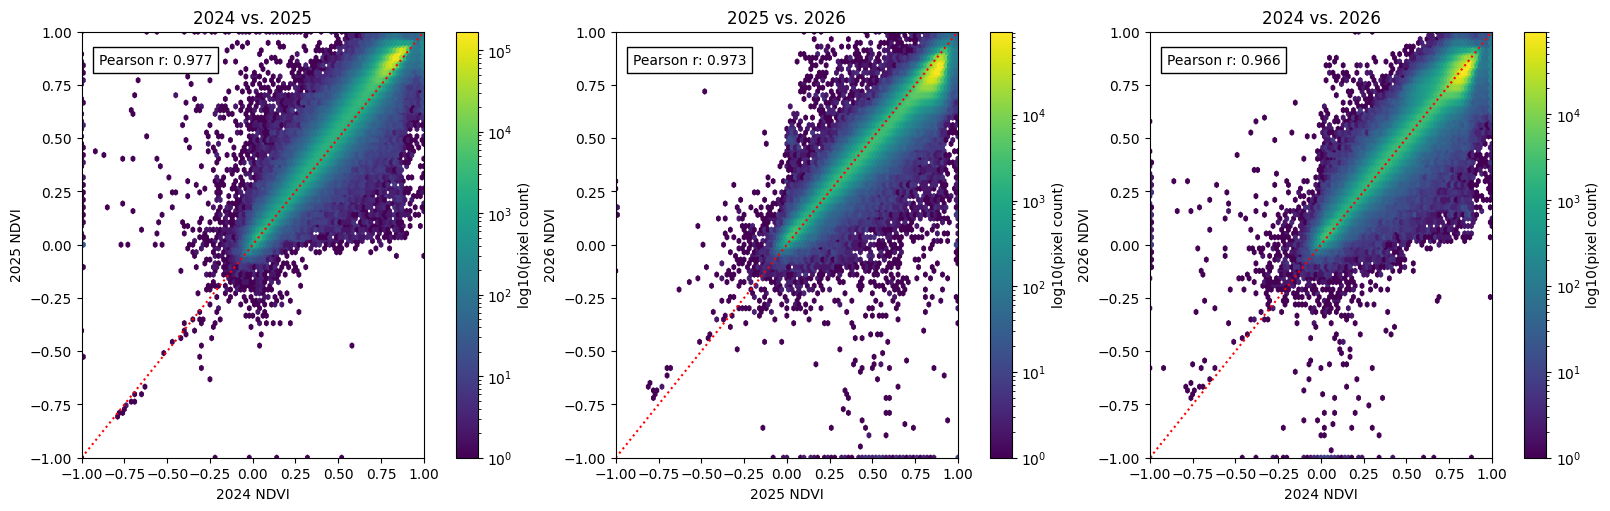

In [128]:
# NDVI correlation and pearson visualizations between years
comparisons = [(
    years[start], years[end], ndvi_crop[start], ndvi_crop[end]) 
    for start, end in date_pairs
]

# Data visualization for NDVI correlation and pearson coefficients
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=100, layout="constrained")

for ax, (year1, year2, ndvi1, ndvi2) in zip(axes, comparisons):
    # Select valid pixels for correlation and compute Pearson correlation coefficient
    x = ndvi1[valid_ndvi_temporal] 
    y = ndvi2[valid_ndvi_temporal]
    P_coef = np.corrcoef(x, y)[0, 1]

    # Create hexbin plot for efficient visualization of large datasets
    hb = ax.hexbin(x, y, gridsize=100, bins="log", mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=ax, label="log10(pixel count)")

    # Set plot labels and features for Pearson correlation coefficients
    ax.plot([-1, 1], [-1, 1], "r:")
    ax.text(
        0.05, 0.95, f"Pearson r: {P_coef:.3f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", alpha=1),
    )
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_xlabel(f"{year1} NDVI")
    ax.set_ylabel(f"{year2} NDVI")
    ax.set_title(f"{year1} vs. {year2}")

    # Print Pearson correlation coefficient and number of valid pixels    
    print(
        f"Pearson correlation ({year1} vs. {year2}): {P_coef:.3f} | Valid pixels: {len(x)}\n"
        f"Spearman {spearmanr(x, y)[0]}"
        )

plt.show()

Pearson correlation (Elevation (m) vs. Slope (degrees)): 0.694 | Valid pixels: 2318682
Spearman 0.7228527756302303
Pearson correlation (2026 NDVI vs. Elevation (m)): 0.396 | Valid pixels: 2318682
Spearman 0.25243888231223766
Pearson correlation (2026 NDVI vs. Slope (degrees)): 0.440 | Valid pixels: 2318682
Spearman 0.3193219918209484


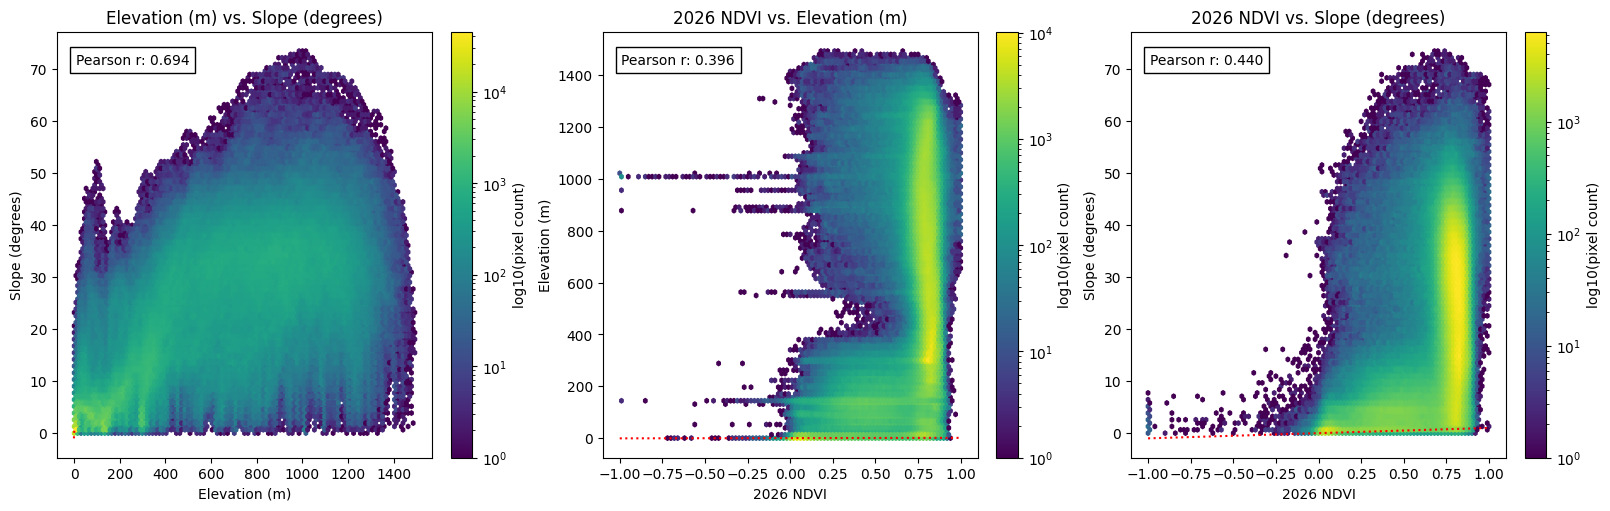

In [ ]:
# Terrain correlation and pearson visualizations using 2026 NDVI for reference
comparisons = [
    ("Elevation (m)", "Slope (degrees)", elevation_crop, slope_gdal_array),
    ("2026 NDVI", "Elevation (m)", ndvi_crop[2], elevation_crop),
    ("2026 NDVI", "Slope (degrees)", ndvi_crop[2], slope_gdal_array),
]

# Data visualization for terrain:slope:2026-NDVI correlation and pearson coefficients
fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), dpi=100, layout="constrained"
)

for ax, (x_name, y_name, x_raster, y_raster) in zip(axes, comparisons):
    # Select valid pixels for correlation and compute Pearson correlation coefficient
    x = x_raster[shared_mask]
    y = y_raster[shared_mask]
    P_coef = np.corrcoef(x, y)[0, 1]

    # Create hexbin plot for efficient visualization of large datasets
    hb = ax.hexbin(x, y, gridsize=100, bins="log", mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=ax, label="log10(pixel count)")

    # Set plot labels for Pearson correlation coefficients
    ax.text(
        0.05, 0.95, f"Pearson r: {P_coef:.3f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", alpha=1),
    )

    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_title(f"{x_name} vs. {y_name}")

    # Print Pearson correlation coefficient and number of valid pixels    
    print(
        f"Pearson correlation ({x_name} vs. {y_name}): "
        f"{P_coef:.3f} | Valid pixels: {len(x)}\n"
        f"Spearman {spearmanr(x, y)[0]}"
    )

plt.show()

### K-Means Clustering and Correlation

#### K-Means Clustering Correlation

In [130]:
# Create features matrix for K-Means clustering using NDVI, DEM, and slope data
features = np.stack(
    [
        ndvi_crop[0],
        ndvi_crop[1],
        ndvi_crop[2],
        elevation_crop,
        slope_gdal_array
    ],
    axis = -1
)

# Create a valid mask for features to ensure all values are finite
valid_mask_features = np.all(np.isfinite(features), axis=-1)
finite_training_features = features[valid_mask_features]

# Standardize the features using StandardScaler
scaler = StandardScaler()
features_scaled = scaler.fit_transform(finite_training_features)

# Verify training features and standardized features shapes
print(
    f"Finite training features shape: {finite_training_features.shape}\n"
    f"Standardized features shape: {features_scaled.shape}"
)

Finite training features shape: (2318682, 5)
Standardized features shape: (2318682, 5)


In [144]:
# Run K-Means clustering on the standardized features
model_cluster_corr = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=3
)

In [146]:
# Store cluster labels for each pixel in the valid mask
cluster_labels = model_cluster_corr.fit_predict(features_scaled)

cluster_map_corr = np.full(
    valid_mask_features.shape,
    np.nan,
    dtype=np.float32
)

cluster_map_corr[valid_mask_features] = cluster_labels

In [150]:
# Invert standardization to get cluster centers in original units
centres_cluster_corr = scaler.inverse_transform(model_cluster_corr.cluster_centers_)

# Prepare DataFrame for cluster centers and correlation statistics
feature_names = [
    "NDVI 2024", "NDVI 2025", "NDVI 2026",
    "Elevation (m)", "Slope (degrees)"
]

cluster_centres_df = pd.DataFrame(
    centres_cluster_corr, 
    columns=feature_names,
    index=[f"Cluster {i}" for i in range(model_cluster_corr.n_clusters)],
)

cluster_centres_df

,NDVI 2024,NDVI 2025,NDVI 2026,Elevation (m),Slope (degrees)
Cluster 0,0.804647,0.844343,0.787804,880.451416,32.189732
Cluster 1,0.175509,0.184635,0.183167,126.000648,4.540499
Cluster 2,0.826066,0.869879,0.809228,355.818939,13.938554
Cluster 3,0.505239,0.532443,0.503169,175.068619,6.468483


In [151]:
# Create datframe for correlation analysis and compute Pearson correlation coefficients
df_corr = pd.DataFrame(finite_training_features, columns=feature_names)
df_corr["Cluster"] = cluster_labels
pearson_corr = df_corr[feature_names].corr(method="pearson")

display(pearson_corr.round(3))

,NDVI 2024,NDVI 2025,NDVI 2026,Elevation (m),Slope (degrees)
NDVI 2024,1.000,0.977,0.966,0.409,0.428
NDVI 2025,0.977,1.000,0.973,0.402,0.430
NDVI 2026,0.966,0.973,1.000,0.396,0.440
Elevation (m),0.409,0.402,0.396,1.000,0.694
Slope (degrees),0.428,0.430,0.440,0.694,1.000


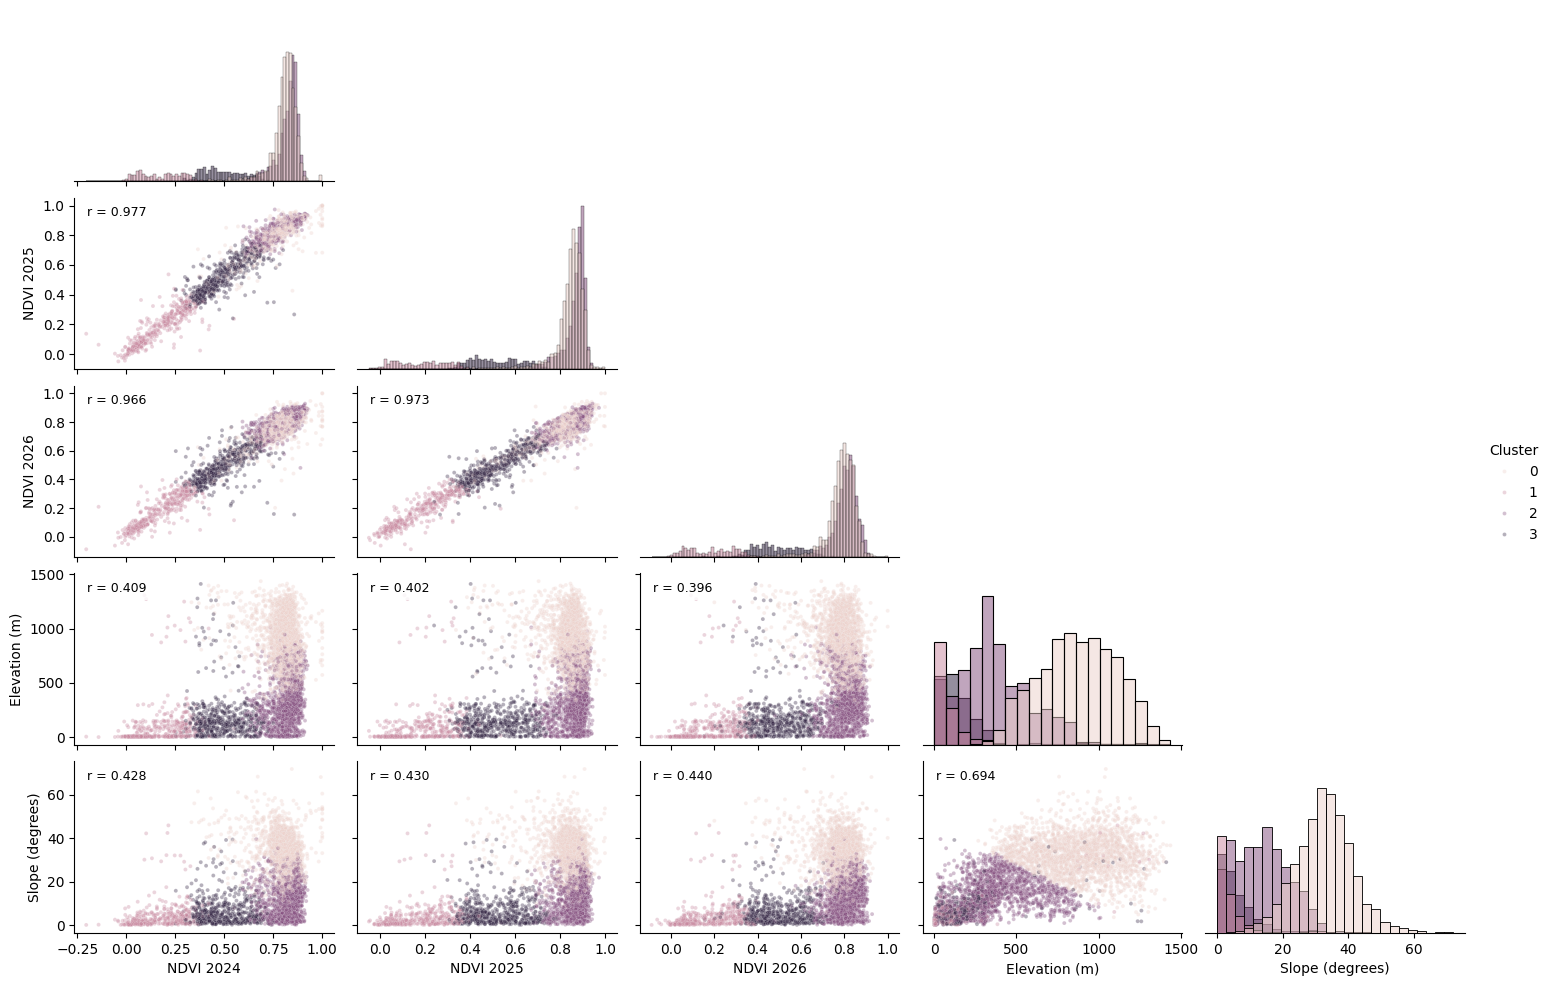

In [154]:
# Create sample of pixels for correlation analysis to avoid overplotting in pairplot
cluster_corr_data = df_corr.sample(
    n=min(5000, len(df_corr)),
    random_state=42,
)

# Create pairplot for correlation analysis with cluster labels
corr_plots = sns.pairplot(
    cluster_corr_data,
    vars=feature_names,
    hue="Cluster",
    corner=True,
    height=2,
    aspect=1.5,
    plot_kws={"alpha": 0.35, "s": 8},
    diag_kind="hist",
)

# Loop over pairplots to annotate Pearson correlation coefficients
for i, j in zip(*np.tril_indices(len(feature_names), k=-1)):
    ax = corr_plots.axes[i, j]
    r = pearson_corr.iloc[i, j] 

    ax.annotate(
        f"r = {r:.3f}",
        xy=(0.05, 0.95),
        xycoords="axes fraction",
        ha="left",
        va="top",
        fontsize=9,
        bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
        )
    )
    
plt.show()

#### K-Means NDVI Clustering

In [158]:
# Create array to store reshaped NDVI datasets for K-Means clustering
ndvi_all = []

for ndvi_dataset in ndvi_crop:
    ndvi_values = ndvi_dataset[valid_ndvi_temporal]
    reshaped_ndvi = ndvi_values.reshape(-1, 1)

    print(
        f"NDVI dataset shape: {ndvi_dataset.shape}, "
        f"Valid pixels: {valid_ndvi_mask.size}, "
        f"Reshaped to: {reshaped_ndvi.shape}"
    )

    ndvi_all.append(reshaped_ndvi)

ndvi_pooled = np.vstack(ndvi_all)

NDVI dataset shape: (2486, 1043), Valid pixels: 2347240, Reshaped to: (2347240, 1)
NDVI dataset shape: (2486, 1043), Valid pixels: 2347240, Reshaped to: (2347240, 1)
NDVI dataset shape: (2486, 1043), Valid pixels: 2347240, Reshaped to: (2347240, 1)


In [162]:
# Run K-Means clustering on the reshaped NDVI datasets
model = KMeans(n_clusters=4, random_state=42, n_init="auto")
model.fit(ndvi_pooled)

,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [166]:
# Store cluster labels
cluster_maps = []

for ndvi_crop_dataset, reshaped_ndvi in zip(ndvi_crop, ndvi_all):
    cluster_map_array = np.full(ndvi_crop_dataset.shape, np.nan)

    cluster_map_array[valid_ndvi_temporal] = model.predict(reshaped_ndvi)
    cluster_maps.append(cluster_map_array)

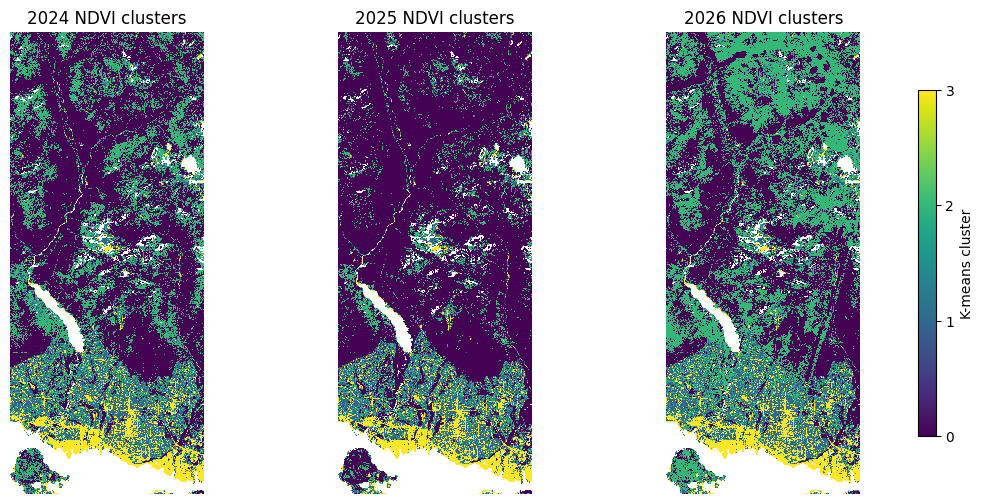

In [167]:
# Data visualization for K-Means clustering results
fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=100)

for ax, year, year_map in zip(axes, years, cluster_maps):
    # Select dataset and specify axis labels
    im = ax.imshow(year_map, cmap="viridis", vmin=0, vmax=model.n_clusters - 1, interpolation="nearest")
    ax.set_title(f"{year} NDVI clusters")
    ax.axis("off")

# Create a colorbar for the cluster maps
fig.colorbar(
    im, ax=axes, ticks=range(model.n_clusters),
    label="K-means cluster", shrink=0.75
)

plt.show()

In [172]:
# Get labels and cluster centers from model clusters
for label, center in enumerate(model.cluster_centers_.ravel()):
    print(f"Cluster {label}: center NDVI = {center:.3f}")

Cluster 0: center NDVI = 0.855
Cluster 1: center NDVI = 0.472
Cluster 2: center NDVI = 0.749
Cluster 3: center NDVI = 0.159


In [173]:
# Create a valid mask for NDVI clusters
valid_ndvi_clusters = np.logical_and.reduce(
    [np.isfinite(cluster_map) for cluster_map in cluster_maps]
)

In [175]:
# Store counts of pixels in each cluster for each year
counts_by_year = {
    year: np.bincount(
            cluster_map[valid_ndvi_clusters].astype(np.intp),
            minlength=model.n_clusters,
        )
    for year, cluster_map in zip(years, cluster_maps)
}

# Compute percent change between years for each cluster
percent_change_by_pair = {
    f"{years[start]}-{years[end]} % Change": np.divide(
        counts_by_year[years[end]] - counts_by_year[years[start]],
        counts_by_year[years[start]],
        out=np.full(model.n_clusters, np.nan),
        where=counts_by_year[years[start]] != 0,
    ) * 100
    for start, end in date_pairs
}

# Store dictionaries in a DataFrame for tabular results
cluster_counts = pd.DataFrame(
    {**counts_by_year, **percent_change_by_pair},
    index=[f"Cluster {i}" for i in range(model.n_clusters)],
)

# Create colour change for DataFrame display based on percent change values
def color_change(value):
    if pd.isna(value) or value == 0:
        return ""
    return "background-color: #d9534f; color: white;" if value < 0 else "background-color: #5cb85c; color: white;"

target_cols = ["2024-2025 % Change", "2025-2026 % Change", "2024-2026 % Change"]

cluster_counts.style.map(
    color_change,
    subset=target_cols,
).format(
    lambda x: f"{abs(x):.2f}%" if pd.notna(x) else "", # report negative values as positive for percent change, keeping colour coding
    subset=target_cols
)

,2024,2025,2026,2024-2025 % Change,2025-2026 % Change,2024-2026 % Change
Cluster 0,1314777,1684462,1025648,28.12%,39.11%,21.99%
Cluster 1,252440,226237,257269,10.38%,13.72%,1.91%
Cluster 2,621481,286586,908770,53.89%,217.10%,46.23%
Cluster 3,158542,149955,155553,5.42%,3.73%,1.89%


### RandomForest Classification against Dynamic World V1 **

## Export Datasets to QGIS and Blender 

In [549]:
np.savez_compressed(
    r"Data Export\export_inputs.npz",
    elevation_crop=elevation_crop,
    slope_gdal_array=slope_gdal_array,
    ndvi_2024=ndvi_crop[0],
    ndvi_2025=ndvi_crop[1],
    ndvi_2026=ndvi_crop[2],
    dw_crop=dw_crop,
    sentinel_transform=np.array(tuple(sentinel_transform)[:6]),
    sentinel_crs=sentinel_crs.to_wkt(),
    col0=col0,
    row0=row0,
)